# Total model fine-tuning notebook

Same two-stage training as `train_tot.py`, in the familiar notebook layout.
The supplied vision and GT-pose checkpoints are loaded once. The first
`ADAPT_EPOCHS` adapt pose with frozen/eval-mode vision; the remaining epochs
fine-tune all modules. `NUM_EPOCHS` includes both stages.


In [1]:
%reload_ext autoreload
%autoreload 2

import argparse
import json
import os
import random
import numpy as np
import time
import torch
from torch.utils.data import DataLoader
from dataset import SceneTwoPairsDataset
from augmentations import build_train_transform, build_eval_transform
from model_pose import PairImageCylinderModel
from metrics import relative_cylinder_errors
from losses import (
    vision_loss,
    patch_correspondence_loss,
    relative_depth_structure_loss,
    matched_depth_delta_loss,
    masked_relative_pose_loss_2d,
)
from pathlib import Path
from types import SimpleNamespace
import matplotlib.pyplot as plt
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text


In [2]:
# -----------------------------------------------------------------------------
# Configuration
# -----------------------------------------------------------------------------
DATA_DIR = Path(".")
OUTPUT_DIR = Path("runs/total_finetune")
VISION_CHECKPOINT = Path("runs/vision_geometry/checkpoints/best_vision.pt")
POSE_CHECKPOINT = Path("runs/pose_only/checkpoints/best.pt")

BATCH_SIZE = 32
NUM_EPOCHS = 100  # Total: 10 adaptation + 90 joint epochs below.
ADAPT_EPOCHS = 10
ADAPT_LEARNING_RATE = 1e-4
LEARNING_RATE = 1e-5  # Vision LR during joint fine-tuning.
POSE_LEARNING_RATE = 1e-5  # Pose LR during joint fine-tuning.
VAL_INTERVAL = 10
SAVE_EVERY = 10
SEED = 0
NUM_WORKERS = 4
IMG_SIZE = 128
PATCH_SIZE = (16, 4)
NUM_BINS = 128
EMBED_DIM = 192
DEPTH = 4
NUM_HEADS = 4
DROPOUT = 0.1

LAMBDA_OCC = 10.0
LAMBDA_RADIUS = 10.0
OCC_THRESH = 0.5
LAMBDA_CORR = 1.0
LAMBDA_POSE = 2.0
LAMBDA_DEPTH_DELTA = 0.35
LAMBDA_WIDTH = 0.1

BEST_MODEL_PATH = str(OUTPUT_DIR / "checkpoints" / "best.pt")
LATEST_MODEL_PATH = str(OUTPUT_DIR / "checkpoints" / "latest.pt")
BEST_ADAPT_PATH = str(OUTPUT_DIR / "checkpoints" / "best_adapt.pt")
INFERENCE_MODEL = "best"  # "best", "latest", or "best_adapt"
INFERENCE_BATCH_SIZE = 4
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
VISION_SAMPLE_IDX = 0
FOREST_ENABLED = False
FOREST_START_EPOCH = 310
FOREST_SAMPLE_IDX = 0
FOREST_OCC_THRESHOLD = 0.3

args = SimpleNamespace(
    data_dir=str(DATA_DIR),
    output_dir=str(OUTPUT_DIR),
    vision_checkpoint=str(VISION_CHECKPOINT),
    pose_checkpoint=str(POSE_CHECKPOINT),
    epochs=NUM_EPOCHS,
    adapt_epochs=ADAPT_EPOCHS,
    adapt_lr=ADAPT_LEARNING_RATE,
    lr=LEARNING_RATE,
    pose_lr=POSE_LEARNING_RATE,
    batch_size=BATCH_SIZE,
    val_interval=VAL_INTERVAL,
    save_every=SAVE_EVERY,
    seed=SEED,
    num_workers=NUM_WORKERS,
    img_size=IMG_SIZE,
    patch_size=PATCH_SIZE,
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    num_heads=NUM_HEADS,
    num_bins=NUM_BINS,
    dropout=DROPOUT,
    lambda_occ=LAMBDA_OCC,
    lambda_radius=LAMBDA_RADIUS,
    occ_thresh=OCC_THRESH,
    lambda_corr=LAMBDA_CORR,
    lambda_depth_delta=LAMBDA_DEPTH_DELTA,
    lambda_pose=LAMBDA_POSE,
    lambda_width=LAMBDA_WIDTH,
)


In [ ]:
# Check component settings, configure device and seeds (same as train_tot.py).
parser = argparse.ArgumentParser()
if not 0 <= args.adapt_epochs < args.epochs:
    parser.error("Require 0 <= --adapt-epochs < --epochs (total epoch count)")

if min(args.lr, args.adapt_lr, args.lambda_pose) <= 0:
    parser.error("Learning rates and --lambda-pose must be positive")

args.pose_lr = args.lr if args.pose_lr is None else args.pose_lr

if args.pose_lr <= 0 or min(args.val_interval, args.save_every, args.batch_size) < 1:
    parser.error("Pose learning rate, intervals and batch size must be positive")

pose_saved = torch.load(args.pose_checkpoint, map_location="cpu", weights_only=False)

if "model_config" not in pose_saved:
    parser.error("--pose-checkpoint must be the standalone matched-pair pose checkpoint")

pose_cfg = pose_saved["model_config"]

args.pose_embed_dim = pose_cfg["embed_dim"]
args.pose_num_heads = pose_cfg["num_heads"]
args.pose_depth = pose_cfg["depth"]
args.pose_dropout = pose_cfg["dropout"]
args.fov_degrees = pose_cfg["fov_degrees"]
args.radius_scale = pose_cfg["radius_scale"]
args.distance_scale = pose_cfg["distance_scale"]

vision_saved = torch.load(args.vision_checkpoint, map_location="cpu", weights_only=False)
vision_cfg = vision_saved.get("args", {})

for key in ("img_size", "patch_size", "embed_dim", "depth", "num_heads", "num_bins", "dropout"):
    if key in vision_cfg:
        saved_value, requested_value = (vision_cfg[key], getattr(args, key))
        if key == "patch_size":
            saved_value, requested_value = (tuple(saved_value), tuple(requested_value))
        if saved_value != requested_value:
            parser.error(
                f"Vision checkpoint {key}={saved_value}, but script uses {requested_value}; "
                f"set --{key.replace('_', '-')} to match"
            )

if abs(vision_cfg.get("fov_degrees", 90.0) - args.fov_degrees) > 1e-06:
    parser.error("Vision and pose checkpoints must use the same field of view")

del vision_saved

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.set_float32_matmul_precision("high")

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

os.makedirs(args.output_dir, exist_ok=True)

os.makedirs(os.path.join(args.output_dir, "checkpoints"), exist_ok=True)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

random.seed(args.seed)
np.random.seed(args.seed)
torch.manual_seed(args.seed)
torch.cuda.manual_seed_all(args.seed)

print("Seed: ", args.seed)


Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
CUDA: 13.0
Seed:  0


In [4]:
# This run initializes from the two separate pretraining checkpoints.
# It does not resume an earlier fine-tuning optimizer, just like train_tot.py.
print("Vision checkpoint:", VISION_CHECKPOINT)
print("GT-pose checkpoint:", POSE_CHECKPOINT)
print(f"Epochs 1–{ADAPT_EPOCHS}: pose adaptation; then joint tuning through epoch {NUM_EPOCHS}.")


Vision checkpoint: runs/vision_geometry/checkpoints/best_vision.pt
GT-pose checkpoint: runs/pose_only/checkpoints/best.pt
Epochs 1–10: pose adaptation; then joint tuning through epoch 100.


## Data

Data loaders and the composed model are initialized in the same order as
`train_tot.py`. The optional forest loader is only for visualization.


In [5]:
train_dataset = SceneTwoPairsDataset(
    root_dir=os.path.join(args.data_dir, "dataset"),
    image_size=args.img_size,
    debug=False,
    return_two_pairs=False,
    transform=build_train_transform(args.img_size),
)

val_dataset = SceneTwoPairsDataset(
    root_dir=os.path.join(args.data_dir, "valdataset"),
    image_size=args.img_size,
    debug=False,
    return_two_pairs=False,
    transform=build_eval_transform(args.img_size),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=args.batch_size,
    shuffle=True,
    num_workers=args.num_workers,
    pin_memory=device.type == "cuda",
    persistent_workers=args.num_workers > 0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=args.batch_size,
    shuffle=False,
    num_workers=args.num_workers,
    pin_memory=device.type == "cuda",
    persistent_workers=args.num_workers > 0,
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

model = PairImageCylinderModel(
    img_size=args.img_size,
    patch_size=args.patch_size,
    in_chans=3,
    embed_dim=args.embed_dim,
    depth=args.depth,
    num_heads=args.num_heads,
    num_bins=args.num_bins,
    dropout=args.dropout,
    pose_embed_dim=args.pose_embed_dim,
    pose_num_heads=args.pose_num_heads,
    pose_depth=args.pose_depth,
    pose_dropout=args.pose_dropout,
    fov_degrees=args.fov_degrees,
    radius_scale=args.radius_scale,
    distance_scale=args.distance_scale,
).to(device)

model.load_vision_checkpoint(args.vision_checkpoint)

model.pose_head.load_state_dict(pose_saved["model_state_dict"], strict=True)

print("Loaded vision weights:", args.vision_checkpoint)
print("Loaded GT-pose weights:", args.pose_checkpoint)

del pose_saved

n_params = sum((p.numel() for p in model.parameters()))

print(f"Model parameters: {n_params / 1000000.0:.2f} M")

raw_model = model

vision_parameters = (
    list(model.backbone.parameters()) + list(model.vision_head.parameters()) + list(model.corr_decoder.parameters())
)

optimizer = torch.optim.AdamW(
    [
        {"params": vision_parameters, "lr": args.lr, "name": "vision"},
        {"params": list(model.pose_head.parameters()), "lr": args.adapt_lr, "name": "pose"},
    ],
    weight_decay=0.05,
)

scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

forest_loader = None
if FOREST_ENABLED:
    from colmap_pair_dataset import ColmapPairDataset

    forest_dataset = ColmapPairDataset(dataset_dir="forestdataset_torpa", image_size=IMG_SIZE)
    forest_loader = DataLoader(forest_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)


Train samples: 4960
Validation samples: 482
Train batches: 155
Validation batches: 16
Loaded vision weights: runs/vision_geometry/checkpoints/best_vision.pt
Loaded GT-pose weights: runs/pose_only/checkpoints/best.pt
Model parameters: 4.36 M


## Training helpers

Batch transfer and freeze/unfreeze behavior are the same as in `train_tot.py`.


In [6]:
def move_batch_to_device(batch, device):
    return tuple((x.to(device, non_blocking=True) for x in batch))


def set_training_stage(model, optimizer, pose_only, args):
    """Freeze vision weights for adaptation; unfreeze all for joint fine-tuning."""
    for module in (model.backbone, model.vision_head, model.corr_decoder):
        module.requires_grad_(not pose_only)
    model.pose_head.requires_grad_(True)
    for group in optimizer.param_groups:
        if group["name"] == "vision":
            group["lr"] = 0.0 if pose_only else args.lr
        elif group["name"] == "pose":
            group["lr"] = args.adapt_lr if pose_only else args.pose_lr


In [7]:
@torch.no_grad()
def validate(
    model,
    loader,
    device,
    occ_thresh,
    lambda_occ,
    lambda_radius,
    lambda_corr,
    lambda_depth_delta,
    lambda_pose,
    lambda_width,
    pose_only=False,
):
    model.eval()
    totals = {
        "total": 0.0,
        "vision": 0.0,
        "vision_occupancy": 0.0,
        "vision_radius": 0.0,
        "vision_depth": 0.0,
        "vision_width": 0.0,
        "objective": 0.0,
        "correspondence": 0.0,
        "depth_structure": 0.0,
        "depth_delta": 0.0,
        "pose": 0.0,
        "translation": 0.0,
        "rotation": 0.0,
        "cylinder_radius_rel_l2": 0.0,
        "cylinder_position_rel_l2": 0.0,
    }
    num_batches = 0
    for batch in loader:
        img_a, vision_a, img_b, vision_b, pose_ab = move_batch_to_device(batch, device)
        pred_vision_a, pred_vision_b, pred_pose, corr_a, corr_b, pose_info = model(
            img_a,
            img_b,
            return_corr=True,
            compute_pose=lambda_pose != 0,
            target_vision_a=vision_a,
            target_vision_b=vision_b,
            return_pose_inputs=True,
            occ_thresh=occ_thresh,
        )

        vis_a, occ_a, rad_a, dep_a, width_a = vision_loss(
            pred_vision_a,
            vision_a,
            occ_thresh=occ_thresh,
            lambda_occ=lambda_occ,
            lambda_radius=lambda_radius,
            lambda_depth=1.0,
            lambda_width=lambda_width,
        )
        vis_b, occ_b, rad_b, dep_b, width_b = vision_loss(
            pred_vision_b,
            vision_b,
            occ_thresh=occ_thresh,
            lambda_occ=lambda_occ,
            lambda_radius=lambda_radius,
            lambda_depth=1.0,
            lambda_width=lambda_width,
        )

        vision_loss_total = 0.5 * (vis_a + vis_b)
        corr_loss = patch_correspondence_loss(corr_a, vision_a, corr_b, vision_b)
        depth_structure_loss = 0.5 * (
            relative_depth_structure_loss(pred_vision_a, vision_a, occ_thresh)
            + relative_depth_structure_loss(pred_vision_b, vision_b, occ_thresh)
        )
        depth_delta_loss = matched_depth_delta_loss(pred_vision_a, vision_a, pred_vision_b, vision_b, occ_thresh)

        if lambda_pose != 0:
            pose_total, t_loss, r_loss = masked_relative_pose_loss_2d(
                pred_pose, pose_ab, pose_info["pose_valid"], t_weight=1.0, r_weight=1.0
            )
        else:
            pose_total = vision_loss_total.new_zeros(())
            t_loss = vision_loss_total.new_zeros(())
            r_loss = vision_loss_total.new_zeros(())

        total_loss = (
            vision_loss_total
            + lambda_corr * corr_loss
            + 0.5 * depth_structure_loss
            + lambda_depth_delta * depth_delta_loss
            + lambda_pose * pose_total
        )
        radius_a, position_a = relative_cylinder_errors(pred_vision_a, vision_a, occ_thresh)
        radius_b, position_b = relative_cylinder_errors(pred_vision_b, vision_b, occ_thresh)
        objective = lambda_pose * pose_total if pose_only else total_loss

        totals["objective"] += objective.item()
        totals["total"] += total_loss.item()
        totals["vision"] += vision_loss_total.item()
        totals["vision_occupancy"] += (0.5 * (occ_a + occ_b)).item()
        totals["vision_radius"] += (0.5 * (rad_a + rad_b)).item()
        totals["vision_depth"] += (0.5 * (dep_a + dep_b)).item()
        totals["vision_width"] += (0.5 * (width_a + width_b)).item()
        totals["correspondence"] += corr_loss.item()
        totals["depth_structure"] += depth_structure_loss.item()
        totals["depth_delta"] += depth_delta_loss.item()
        totals["pose"] += pose_total.item()
        totals["translation"] += t_loss.item()
        totals["rotation"] += r_loss.item()
        totals["cylinder_radius_rel_l2"] += (0.5 * (radius_a + radius_b)).item()
        totals["cylinder_position_rel_l2"] += (0.5 * (position_a + position_b)).item()

        num_batches += 1

    if num_batches == 0:
        raise RuntimeError("Validation loader is empty.")
    metrics = {key: value / num_batches for key, value in totals.items()}
    return metrics


## Training

In [8]:
metric_names = ("vision_occupancy", "vision_radius", "vision_depth", "vision_width")
history = {
    key: []
    for key in (
        "epoch",
        "stage",
        "vision_lr",
        "pose_lr",
        "objective",
        "loss",
        "vision_loss",
        "correspondence_loss",
        "depth_structure_loss",
        "depth_delta_loss",
        "pose_loss",
        "translation_loss",
        "rotation_loss",
        "val_epoch",
        "val_stage",
        "val_objective",
        "val_total",
        "val_vision",
        "val_correspondence",
        "val_depth_structure",
        "val_depth_delta",
        "val_pose",
        "val_translation",
        "val_rotation",
    )
}
weights = dict(
    vision_occupancy=args.lambda_occ, vision_radius=args.lambda_radius, vision_depth=1.0, vision_width=args.lambda_width
)
for component in metric_names:
    for prefix in ("", "val_"):
        history[prefix + component] = []
        history[prefix + component + "_weighted"] = []
best_val_loss = float("inf")
best_adapt_pose = float("inf")
previous_stage = None
for epoch in range(1, args.epochs + 1):
    epoch_start = time.perf_counter()
    pose_only = epoch <= args.adapt_epochs
    stage = "pose_adapt" if pose_only else "joint"
    set_training_stage(model, optimizer, pose_only, args)
    if stage != previous_stage:
        print(
            f"\nStage: {stage}; vision lr={optimizer.param_groups[0]['lr']:g}; "
            f"pose lr={optimizer.param_groups[1]['lr']:g}",
            flush=True,
        )
        previous_stage = stage
    model.train()
    if pose_only:
        model.backbone.eval()
        model.vision_head.eval()
        model.corr_decoder.eval()
    train_totals = {
        "total": 0.0,
        "vision": 0.0,
        "vision_occupancy": 0.0,
        "vision_radius": 0.0,
        "vision_depth": 0.0,
        "vision_width": 0.0,
        "objective": 0.0,
        "correspondence": 0.0,
        "depth_structure": 0.0,
        "depth_delta": 0.0,
        "pose": 0.0,
        "translation": 0.0,
        "rotation": 0.0,
    }
    for batch in train_loader:
        img_a, vision_a, img_b, vision_b, pose_ab = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            pred_vision_a, pred_vision_b, pred_pose, corr_a, corr_b, pose_info = model(
                img_a,
                img_b,
                return_corr=True,
                compute_pose=args.lambda_pose != 0,
                target_vision_a=vision_a,
                target_vision_b=vision_b,
                return_pose_inputs=True,
                occ_thresh=args.occ_thresh,
            )
            vis_a, occ_a, rad_a, dep_a, width_a = vision_loss(
                pred_vision_a,
                vision_a,
                occ_thresh=args.occ_thresh,
                lambda_occ=args.lambda_occ,
                lambda_radius=args.lambda_radius,
                lambda_depth=1.0,
                lambda_width=args.lambda_width,
            )
            vis_b, occ_b, rad_b, dep_b, width_b = vision_loss(
                pred_vision_b,
                vision_b,
                occ_thresh=args.occ_thresh,
                lambda_occ=args.lambda_occ,
                lambda_radius=args.lambda_radius,
                lambda_depth=1.0,
                lambda_width=args.lambda_width,
            )
            vision_loss_total = 0.5 * (vis_a + vis_b)
            corr_loss = patch_correspondence_loss(corr_a, vision_a, corr_b, vision_b)
            depth_structure_loss = 0.5 * (
                relative_depth_structure_loss(pred_vision_a, vision_a, args.occ_thresh)
                + relative_depth_structure_loss(pred_vision_b, vision_b, args.occ_thresh)
            )
            depth_delta_loss = matched_depth_delta_loss(
                pred_vision_a, vision_a, pred_vision_b, vision_b, args.occ_thresh
            )
            if args.lambda_pose != 0:
                pose_total, t_loss, r_loss = masked_relative_pose_loss_2d(
                    pred_pose, pose_ab, pose_info["pose_valid"], t_weight=1.0, r_weight=1.0
                )
            else:
                pose_total = vision_loss_total.new_zeros(())
                t_loss = vision_loss_total.new_zeros(())
                r_loss = vision_loss_total.new_zeros(())
            loss = (
                vision_loss_total
                + args.lambda_corr * corr_loss
                + 0.5 * depth_structure_loss
                + args.lambda_depth_delta * depth_delta_loss
                + args.lambda_pose * pose_total
            )
        objective = args.lambda_pose * pose_total if pose_only else loss
        valid_pose = pose_info["pose_valid"] & (pose_ab[:, :2].norm(dim=-1) > 1e-06)
        
        if not pose_only or valid_pose.any():
            scaler.scale(objective).backward()
            scaler.step(optimizer)
            scaler.update()
        
        train_totals["objective"] += objective.item()
        train_totals["total"] += loss.item()
        train_totals["vision"] += vision_loss_total.item()
        train_totals["vision_occupancy"] += (0.5 * (occ_a + occ_b)).item()
        train_totals["vision_radius"] += (0.5 * (rad_a + rad_b)).item()
        train_totals["vision_depth"] += (0.5 * (dep_a + dep_b)).item()
        train_totals["vision_width"] += (0.5 * (width_a + width_b)).item()
        train_totals["correspondence"] += corr_loss.item()
        train_totals["depth_structure"] += depth_structure_loss.item()
        train_totals["depth_delta"] += depth_delta_loss.item()
        train_totals["pose"] += pose_total.item()
        train_totals["translation"] += t_loss.item()
        train_totals["rotation"] += r_loss.item()
    
    train_metrics = {key: value / len(train_loader) for key, value in train_totals.items()}
    
    history["epoch"].append(epoch)
    history["stage"].append(stage)
    history["vision_lr"].append(optimizer.param_groups[0]["lr"])
    history["pose_lr"].append(optimizer.param_groups[1]["lr"])
    train_mapping = {
        "objective": "objective",
        "loss": "total",
        "vision_loss": "vision",
        "correspondence_loss": "correspondence",
        "depth_structure_loss": "depth_structure",
        "depth_delta_loss": "depth_delta",
        "pose_loss": "pose",
        "translation_loss": "translation",
        "rotation_loss": "rotation",
    }
    for key, metric in train_mapping.items():
        history[key].append(train_metrics[metric])
    for component, weight in weights.items():
        history[component].append(train_metrics[component])
        history[component + "_weighted"].append(weight * train_metrics[component])
    
    log = (
        f"Epoch {epoch} [{stage}]: obj={train_metrics['objective']:.4f} "
        f"| tot={train_metrics['total']:.4f} | vis={train_metrics['vision']:.4f} "
        f"| occ={train_metrics['vision_occupancy']:.4f} | rad={train_metrics['vision_radius']:.4f} "
        f"| depth={train_metrics['vision_depth']:.4f} | width={train_metrics['vision_width']:.4f} "
        f"| corr={train_metrics['correspondence']:.4f} | struct={train_metrics['depth_structure']:.4f} "
        f"| delta={train_metrics['depth_delta']:.4f} | pose={train_metrics['pose']:.4f}"
    )
    
    improved = improved_adapt = False
    should_validate = (
        epoch == 1 or epoch % args.val_interval == 0 or epoch in (args.adapt_epochs, args.adapt_epochs + 1, args.epochs)
    )
    if should_validate:
        val_metrics = validate(
            model,
            val_loader,
            device,
            args.occ_thresh,
            args.lambda_occ,
            args.lambda_radius,
            args.lambda_corr,
            args.lambda_depth_delta,
            args.lambda_pose,
            args.lambda_width,
            pose_only=pose_only,
        )
        history["val_epoch"].append(epoch)
        history["val_stage"].append(stage)
        for key, metric in {
            "val_objective": "objective",
            "val_total": "total",
            "val_vision": "vision",
            "val_correspondence": "correspondence",
            "val_depth_structure": "depth_structure",
            "val_depth_delta": "depth_delta",
            "val_pose": "pose",
            "val_translation": "translation",
            "val_rotation": "rotation",
        }.items():
            history[key].append(val_metrics[metric])
        for component, weight in weights.items():
            history["val_" + component].append(val_metrics[component])
            history["val_" + component + "_weighted"].append(weight * val_metrics[component])
        log += (
            f" | val_tot={val_metrics['total']:.4f} | val_vis={val_metrics['vision']:.4f} "
            f"| val_occ={val_metrics['vision_occupancy']:.4f} | val_rad={val_metrics['vision_radius']:.4f} "
            f"| val_depth={val_metrics['vision_depth']:.4f} | val_width={val_metrics['vision_width']:.4f} "
            f"| val_pose={val_metrics['pose']:.4f}"
        )
        if pose_only:
            improved_adapt = val_metrics["pose"] < best_adapt_pose
            best_adapt_pose = min(best_adapt_pose, val_metrics["pose"])
        else:
            improved = val_metrics["total"] < best_val_loss
            best_val_loss = min(best_val_loss, val_metrics["total"])
        if improved or improved_adapt:
            log += " | BEST ADAPT" if pose_only else " | BEST JOINT"
    state = {
        "epoch": epoch,
        "training_stage": stage,
        "model_state_dict": raw_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "args": vars(args),
        "history": history,
        "best_val_loss": best_val_loss,
        "best_adapt_pose": best_adapt_pose,
    }
    torch.save(state, os.path.join(args.output_dir, "checkpoints", "latest.pt"))
    if improved:
        torch.save(state, os.path.join(args.output_dir, "checkpoints", "best.pt"))
    if improved_adapt:
        torch.save(state, os.path.join(args.output_dir, "checkpoints", "best_adapt.pt"))
    if epoch % args.save_every == 0 or epoch == args.adapt_epochs:
        torch.save(state, os.path.join(args.output_dir, "checkpoints", f"epoch_{epoch:03d}.pt"))
    with open(os.path.join(args.output_dir, "history.json"), "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)
    print(log + f" | time={time.perf_counter() - epoch_start:.1f}s", flush=True)

# Keep final weights available to the notebook's inference cells.
latest_model_state_dict = {key: value.detach().cpu().clone() for key, value in raw_model.state_dict().items()}



Stage: pose_adapt; vision lr=0; pose lr=0.0001
Epoch 1 [pose_adapt]: obj=0.7587 | tot=9.7109 | vis=6.0641 | occ=0.2281 | rad=0.1130 | depth=2.3016 | width=3.5092 | corr=1.1422 | struct=2.6546 | delta=1.1961 | pose=0.3793 | val_tot=11.0345 | val_vis=6.7306 | val_occ=0.2378 | val_rad=0.1189 | val_depth=2.7880 | val_width=3.7511 | val_pose=0.2555 | BEST ADAPT | time=44.6s
Epoch 2 [pose_adapt]: obj=0.3673 | tot=9.3310 | vis=6.0666 | occ=0.2281 | rad=0.1130 | depth=2.3048 | width=3.5073 | corr=1.1459 | struct=2.6589 | delta=1.2051 | pose=0.1836 | time=38.2s
Epoch 3 [pose_adapt]: obj=0.2467 | tot=9.1986 | vis=6.0590 | occ=0.2280 | rad=0.1128 | depth=2.3004 | width=3.5083 | corr=1.1443 | struct=2.6565 | delta=1.2009 | pose=0.1233 | time=37.9s
Epoch 4 [pose_adapt]: obj=0.1965 | tot=9.1525 | vis=6.0638 | occ=0.2281 | rad=0.1129 | depth=2.3029 | width=3.5065 | corr=1.1443 | struct=2.6542 | delta=1.2019 | pose=0.0983 | time=37.9s
Epoch 5 [pose_adapt]: obj=0.1723 | tot=9.1381 | vis=6.0712 | occ=0

## Load saved training state

Load fine-tuning weights and history for plots/inference. This does not resume training.


In [9]:
latest_checkpoint_path = Path(LATEST_MODEL_PATH)
best_checkpoint_path = Path(BEST_MODEL_PATH)
checkpoint_path = best_checkpoint_path
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    raw_model.load_state_dict(checkpoint["model_state_dict"])
    history = checkpoint["history"]
    best_val_loss = checkpoint.get("best_val_loss", float("inf"))
    best_epoch = checkpoint.get("epoch")
    print(f"Loaded epoch {best_epoch}, stage {checkpoint.get('training_stage')}: {checkpoint_path}")
else:
    print(f"No joint checkpoint at {checkpoint_path}; it is saved during the joint stage.")


Loaded epoch 20, stage joint: runs/total_finetune/checkpoints/best.pt


In [10]:
if False:
    val_epochs = np.array(history["val_epoch"])
    plt.figure(figsize=(10, 5))
    plt.plot(val_epochs, history["val_translation"], ".-", label="Translation loss")
    plt.plot(val_epochs, history["val_rotation"], ".-", label="Yaw loss")
    plt.axvline(ADAPT_EPOCHS + 0.5, color="gray", linestyle=":", label="Joint stage starts")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## Training plots

In [11]:
checkpoint_path = Path(LATEST_MODEL_PATH)
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
raw_model.load_state_dict(checkpoint["model_state_dict"])
history = checkpoint["history"]
best_val_loss = checkpoint.get("best_val_loss", float("inf"))
best_epoch = checkpoint.get("epoch")
latest_model_state_dict = {key: value.detach().cpu().clone() for key, value in raw_model.state_dict().items()}


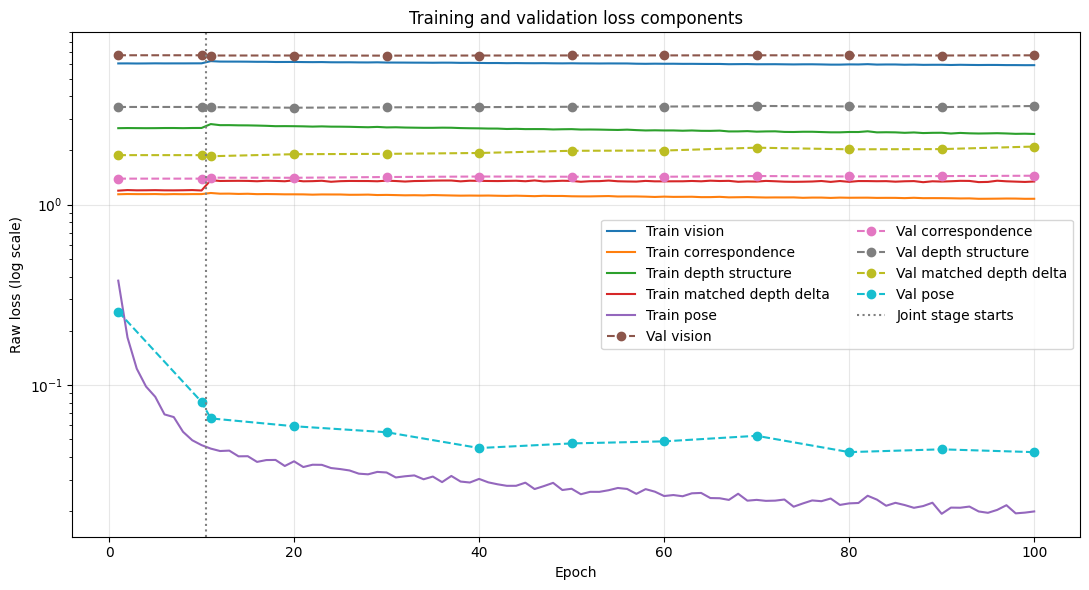

In [12]:
epochs = np.array(history["epoch"])
val_epochs = np.array(history["val_epoch"])
forest_epochs = np.array(history.get("forest_epoch", []))

plt.figure(figsize=(11, 6))

# Train
plt.plot(history["epoch"], history["vision_loss"], label="Train vision")
plt.plot(history["epoch"], history["correspondence_loss"], label="Train correspondence")
plt.plot(history["epoch"], history["depth_structure_loss"], label="Train depth structure")
plt.plot(history["epoch"], history["depth_delta_loss"], label="Train matched depth delta")
plt.plot(history["epoch"], history["pose_loss"], label="Train pose")


# Validation
plt.plot(history["val_epoch"], history["val_vision"], "o--", label="Val vision")
plt.plot(history["val_epoch"], history["val_correspondence"], "o--", label="Val correspondence")
plt.plot(history["val_epoch"], history["val_depth_structure"], "o--", label="Val depth structure")
plt.plot(history["val_epoch"], history["val_depth_delta"], "o--", label="Val matched depth delta")
plt.plot(history["val_epoch"], history["val_pose"], "o--", label="Val pose")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Raw loss (log scale)")
plt.title("Training and validation loss components")
plt.grid(True, alpha=0.3)
if ADAPT_EPOCHS > 0:
    plt.axvline(ADAPT_EPOCHS + 0.5, color="gray", linestyle=":", label="Joint stage starts")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


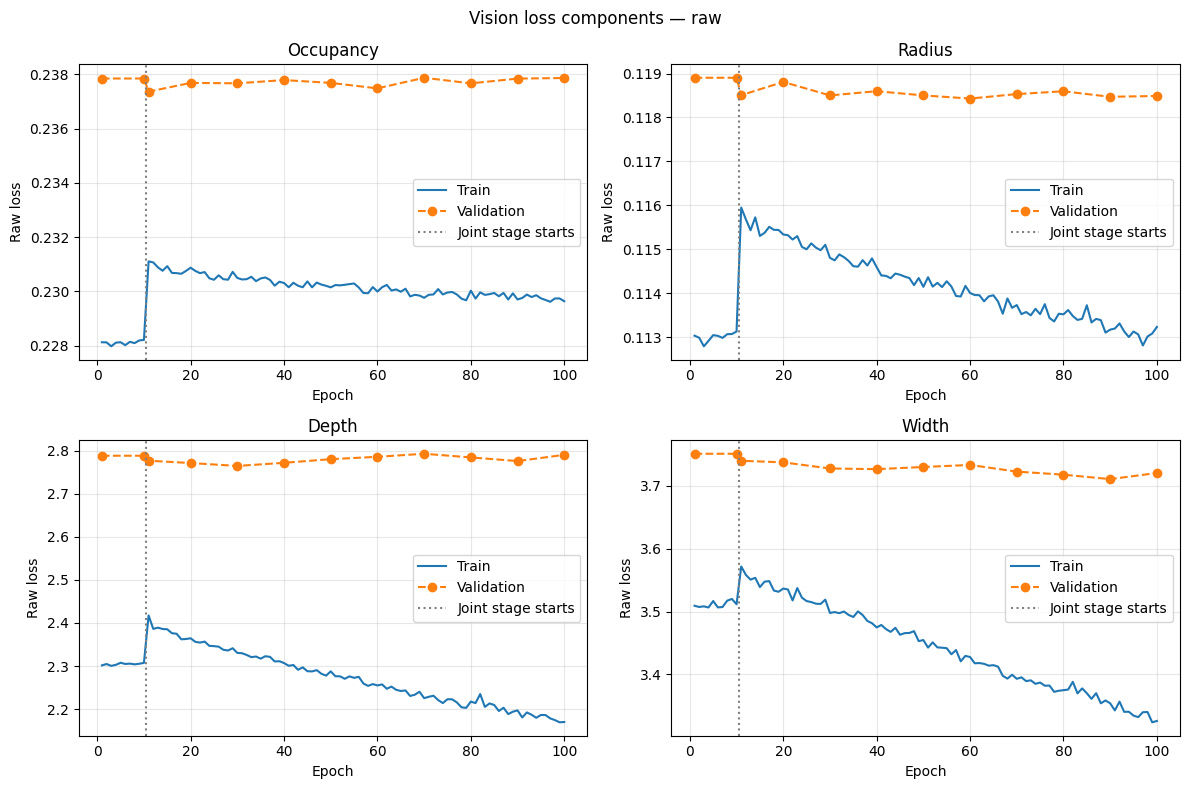

In [13]:
# Separate vision-loss components. False = raw losses; True = actual
# weighted contributions to vision_loss (weights recorded at each epoch).
PLOT_WEIGHTED_VISION = False
suffix = "_weighted" if PLOT_WEIGHTED_VISION else ""
components = [
    ("vision_occupancy", "Occupancy"),
    ("vision_radius", "Radius"),
    ("vision_depth", "Depth"),
    ("vision_width", "Width"),
]
train_epochs = np.asarray(history.get("epoch", []))
validation_epochs = np.asarray(history.get("val_epoch", []))

available = any(
    np.isfinite(np.asarray(history.get(prefix + key + suffix, []), dtype=float)).any()
    for key, _ in components
    for prefix in ("", "val_")
)
if available:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (key, label) in zip(axes.flat, components):
        for prefix, xs, style, legend in (
            ("", train_epochs, "-", "Train"),
            ("val_", validation_epochs, "o--", "Validation"),
        ):
            values = np.asarray(history.get(prefix + key + suffix, []), dtype=float)
            if len(values) == len(xs) and np.isfinite(values).any():
                ax.plot(xs, values, style, label=legend)
        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Weighted contribution" if PLOT_WEIGHTED_VISION else "Raw loss")
        if ADAPT_EPOCHS > 0:
            ax.axvline(ADAPT_EPOCHS + 0.5, color="gray", linestyle=":", label="Joint stage starts")
        ax.grid(True, alpha=0.3)
        if ax.lines:
            ax.legend()
    fig.suptitle("Vision loss components — " + ("weighted" if PLOT_WEIGHTED_VISION else "raw"))
    plt.tight_layout()
    plt.show()
else:
    print("This history has no separate vision components yet. They are recorded from the next training epoch.")


## Inference on test data

In [ ]:
# Choose which trained weights to inspect.
INFERENCE_MODEL = INFERENCE_MODEL.lower()
paths = {"best": BEST_MODEL_PATH, "latest": LATEST_MODEL_PATH, "best_adapt": BEST_ADAPT_PATH}
if INFERENCE_MODEL not in paths:
    raise ValueError("Choose 'best', 'latest' or 'best_adapt'")
checkpoint_path = Path(paths[INFERENCE_MODEL])
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
raw_model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("INFERENCE_MODEL:", INFERENCE_MODEL)
print("Epoch:", checkpoint.get("epoch"), "Stage:", checkpoint.get("training_stage"))

test_dataset = SceneTwoPairsDataset(
    root_dir=os.path.join(args.data_dir, "testdataset"),
    image_size=args.img_size,
    return_two_pairs=False,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
batch = next(iter(test_loader))
img_a, vision_a, img_b, vision_b, pose_ab = (x.to(device) for x in batch)
with torch.no_grad():
    pred_vision, pred_vision_b, pred_pose, pose_info = model(
        img_a,
        img_b,
        target_vision_a=vision_a,
        target_vision_b=vision_b,
        return_pose_inputs=True,
        occ_thresh=OCC_THRESH,
    )


INFERENCE_MODEL: best
Epoch: 20 Stage: joint


## Vision prediction plots

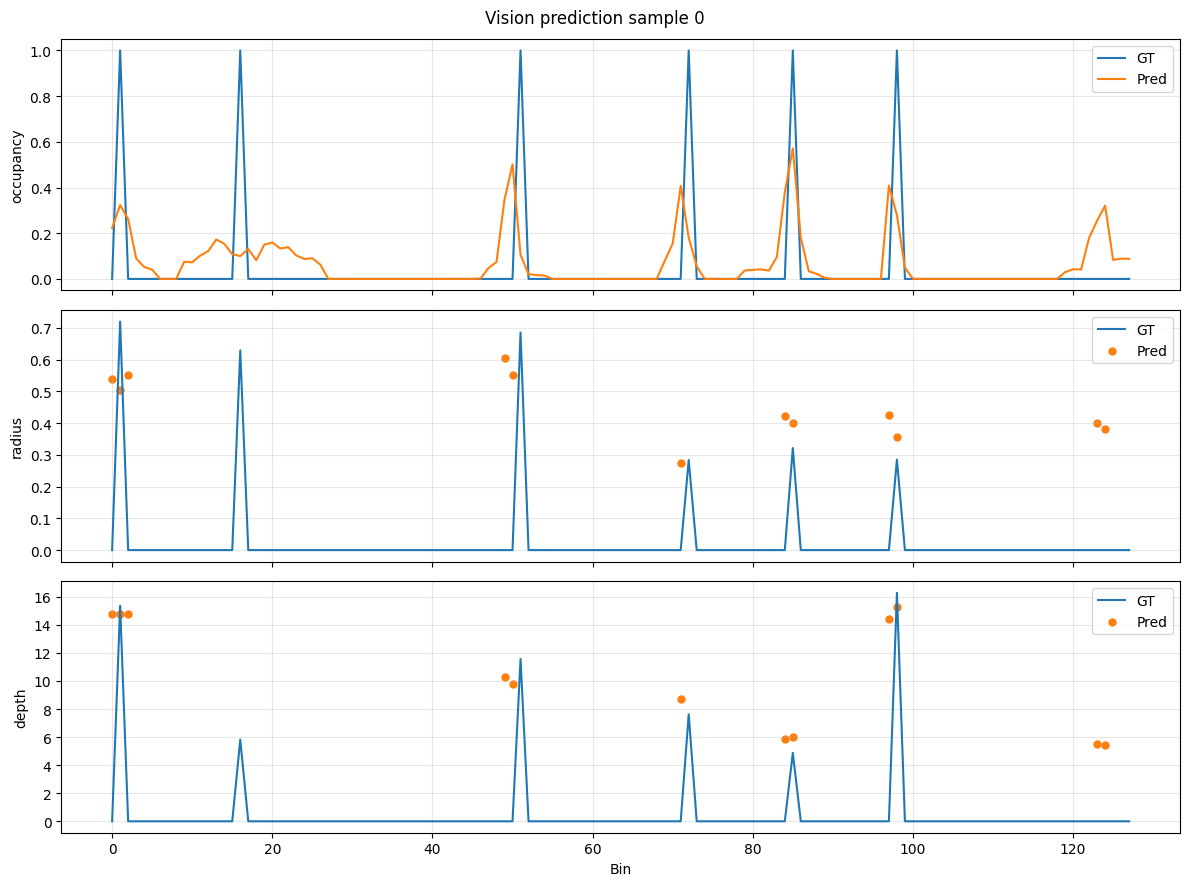

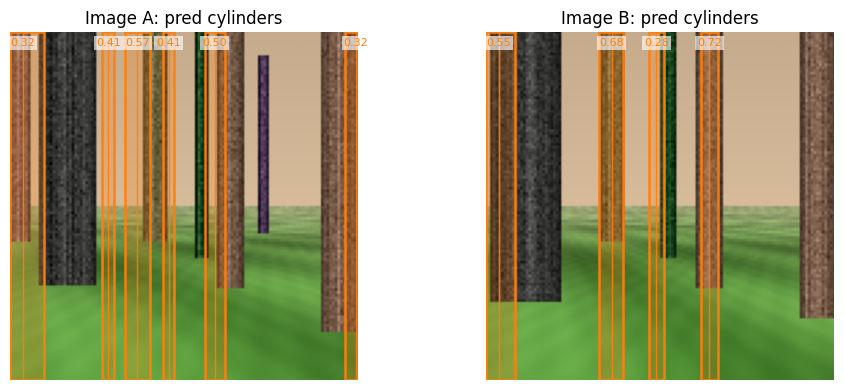

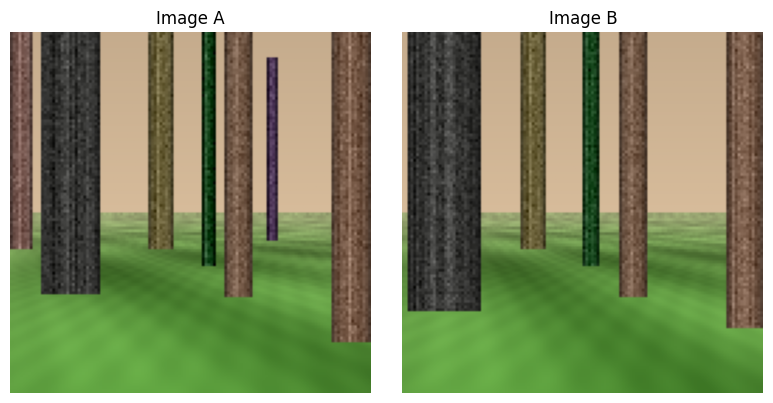

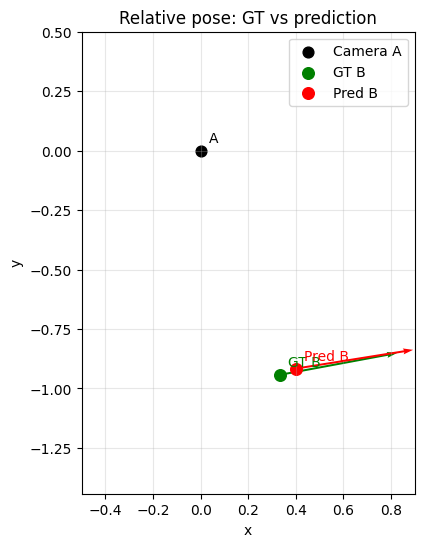

In [22]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(pred_vision.shape[1])
PLOT_OCC_THRESHOLD = 0.2

if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]

    gt_occ = vision_a[sample_idx, :, 0].detach().cpu().numpy()
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()

    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()

        ax.plot(bins, gt, label="GT", color="tab:blue")

        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter(
                bins[pr_mask],
                pr[pr_mask],
                label="Pred",
                color="tab:orange",
                s=25,
            )

        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()

    fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
        [img_a[sample_idx], img_b[sample_idx]],
        [pred_vision[sample_idx], pred_vision_b[sample_idx]],
        titles=["Image A: pred cylinders", "Image B: pred cylinders"],
        occ_threshold=PLOT_OCC_THRESHOLD,
        flip_x=True,
    )
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[sample_idx].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[sample_idx].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    if pose_info["pose_valid"][sample_idx] and pose_ab[sample_idx, :2].norm() > 1e-6:
        plot_relative_pose(pose_ab[sample_idx], pred_pose[sample_idx])
    else:
        print("Selected sample has no evaluable pose; choose another VISION_SAMPLE_IDX.")


In [23]:
from metrics import evaluate_vision

vision_metrics = evaluate_vision(model, test_loader, device, occ_threshold=0.2)



VISION PERFORMANCE

OCCUPANCY, occ_threshold=0.20
------------------------------------------------------------------------------
  Accuracy   Precision    Recall        F1   Recall ±1   Recall ±2
     0.870       0.321     0.427     0.366       0.563       0.624

GEOMETRY
------------------------------------------------------------------------------
                 N       MAE      RMSE      Bias      Corr  Pred std    GT std
Radius       11870     0.122     0.150    -0.001     0.400     0.092     0.161
Depth        11870     2.751     3.937    -0.764     0.703     4.214     5.395

TOLERANCE ACCURACY
------------------------------------------------------------------------------
Radius         ±0.05 m     ±0.10 m     ±0.20 m
                 0.244       0.469       0.803

Depth           ±0.5 m      ±1.0 m      ±2.0 m      ±5.0 m
                 0.178       0.328       0.541       0.824


In [24]:
from metrics import evaluate_pose

pose_metrics = evaluate_pose(model, test_loader, device)


CAMERA POSE PERFORMANCE
Pose method:            Learned pose with GT matches

Test pairs:             514
Successful poses:       514
Prediction failures:    0
Success rate:           1.000
Excluded GT pairs:      13

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   12.22°
Median:                 6.66°
P90:                    29.31°

YAW ERROR
----------------------------------------
Mean:                   1.53°
Median:                 0.94°
P90:                    3.33°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T= 42.0% | Yaw= 94.9%
< 10°: T= 63.4% | Yaw= 99.2%
< 20°: T= 80.0% | Yaw=100.0%
< 30°: T= 90.3% | Yaw=100.0%


## Forest visualization

In [18]:
if FOREST_ENABLED:
    forest_sample_idx = FOREST_SAMPLE_IDX
    model.eval()
    forest_batch = next(iter(forest_loader))
    img_a_forest, img_b_forest, _ = forest_batch

    img_a_forest = img_a_forest.to(device)
    img_b_forest = img_b_forest.to(device)

    with torch.no_grad():
        pred_vision_a_forest, pred_vision_b_forest, pred_pose_forest = model(
            img_a_forest, img_b_forest, compute_pose=False
        )

    fig_forest_cyl, axes_forest_cyl = plot_estimated_cylinders_on_images(
        [
            img_a_forest[forest_sample_idx],
            img_b_forest[forest_sample_idx],
        ],
        [
            pred_vision_a_forest[forest_sample_idx],
            pred_vision_b_forest[forest_sample_idx],
        ],
        titles=["Forest A: pred cylinders", "Forest B: pred cylinders"],
        occ_threshold=FOREST_OCC_THRESHOLD,
        flip_x=True,
    )
    plt.show()

    print("forest pred_vision_a shape:", pred_vision_a_forest.shape)
    print("Forest visualization is vision only: no GT bin matches are available.")


## Notes

- Same two-stage training as `train_tot.py`; the training loop remains visible in its original cell.
- `NUM_EPOCHS` is the total, including the first `ADAPT_EPOCHS`.
- Adaptation: vision weights frozen, vision modules in eval mode; only weighted pose loss is optimized.
- Joint stage: all modules train with the original full weighted loss and the lower learning rates.
- `loss`/`val_total` always record the full joint loss; `objective`/`val_objective` record the
  phase-specific optimization objective.
- The optimizer is preserved across the stage transition.
- `best_adapt.pt` is selected by adaptation pose loss; `best.pt` by joint-stage total loss.
- `latest.pt`, periodic epoch snapshots, and history.json follow the script's saving logic.
- GT bin positions and IDs still specify matches. Radius/depth are predicted; no extra geometry loss is enabled.
- Choose `best`, `latest` or `best_adapt` for inference. Forest remains optional vision-only visualization.


In [19]:
import torch
import numpy as np


@torch.no_grad()
def evaluate_depth(loader, name="VALIDATION", occ_threshold=0.5):
    model.eval()

    pred_all = []
    gt_all = []

    for batch in loader:
        if len(batch) == 5:
            img_a, vision_a, img_b, vision_b, _ = batch

            img_a = img_a.to(device, non_blocking=True)
            img_b = img_b.to(device, non_blocking=True)
            vision_a = vision_a.to(device, non_blocking=True)
            vision_b = vision_b.to(device, non_blocking=True)

            pred_a, pred_b, _ = model(img_a, img_b, compute_pose=False)

            for pred, gt in [(pred_a, vision_a), (pred_b, vision_b)]:
                mask = gt[..., 0] > occ_threshold
                pred_all.append(pred[..., 2][mask].detach().cpu())
                gt_all.append(gt[..., 2][mask].detach().cpu())

        elif len(batch) == 10:
            img_a1, vision_a1, img_b1, vision_b1, _, img_a2, vision_a2, img_b2, vision_b2, _ = batch

            pairs = [
                (img_a1, vision_a1, img_b1, vision_b1),
                (img_a2, vision_a2, img_b2, vision_b2),
            ]

            for img_a, vision_a, img_b, vision_b in pairs:
                img_a = img_a.to(device, non_blocking=True)
                img_b = img_b.to(device, non_blocking=True)
                vision_a = vision_a.to(device, non_blocking=True)
                vision_b = vision_b.to(device, non_blocking=True)

                pred_a, pred_b, _ = model(img_a, img_b, compute_pose=False)

                for pred, gt in [(pred_a, vision_a), (pred_b, vision_b)]:
                    mask = gt[..., 0] > occ_threshold
                    pred_all.append(pred[..., 2][mask].detach().cpu())
                    gt_all.append(gt[..., 2][mask].detach().cpu())

        else:
            raise ValueError(f"Okänt batch-format: {len(batch)}")

    pred = torch.cat(pred_all).float()
    gt = torch.cat(gt_all).float()

    abs_err = (pred - gt).abs()
    rel_err = abs_err / (gt.abs() + 1e-6)

    mae = abs_err.mean().item()
    rmse = torch.sqrt(((pred - gt) ** 2).mean()).item()
    median_ae = abs_err.median().item()
    rel_mae = rel_err.mean().item()
    median_rel = rel_err.median().item()

    pred_centered = pred - pred.mean()
    gt_centered = gt - gt.mean()
    corr = ((pred_centered * gt_centered).mean() / (pred_centered.std() * gt_centered.std() + 1e-8)).item()

    baseline = (gt - gt.mean()).abs().mean().item()

    print(f"\n{name}")
    print("-" * 45)
    print(f"Occupied bins:        {len(gt)}")
    print(f"GT depth mean:        {gt.mean().item():.3f}")
    print(f"GT depth std:         {gt.std().item():.3f}")
    print(f"Pred depth mean:      {pred.mean().item():.3f}")
    print(f"Pred depth std:       {pred.std().item():.3f}")
    print(f"Depth MAE:            {mae:.3f}")
    print(f"Depth RMSE:           {rmse:.3f}")
    print(f"Median abs error:     {median_ae:.3f}")
    print(f"Relative MAE:         {100 * rel_mae:.1f}%")
    print(f"Median relative err:  {100 * median_rel:.1f}%")
    print(f"Depth correlation:    {corr:.3f}")
    print(f"Mean-depth baseline:  {baseline:.3f}")
    print(f"Improvement baseline: {baseline / max(mae, 1e-8):.2f}x")
